# Lab 4

In [1]:
from pathlib import Path

import cv2
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
def load_dataset(task_path, image_size=(128, 128), test_size=0.2, random_state=42):
    class_dirs = sorted(Path(task_path).iterdir())
    class_to_label = {p.name: i for i, p in enumerate(class_dirs)}
    images, labels = [], []

    for class_dir in class_dirs:
        for image_path in sorted(class_dir.glob('*.jpg')):
            image = cv2.imread(str(image_path))
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            image = cv2.resize(image, image_size, interpolation=cv2.INTER_AREA)
            images.append(image)
            labels.append(class_to_label[class_dir.name])

    X = np.asarray(images, dtype=np.float32) / 255.0
    y = np.asarray(labels, dtype=np.int64)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )
    return X_train, X_test, y_train, y_test, class_to_label


## Wczytanie obu zbiorów danych


In [3]:
X_train_1, X_test_1, y_train_1, y_test_1, labels_1 = load_dataset(
    'Task 1 - Simple'
)
X_train_2, X_test_2, y_train_2, y_test_2, labels_2 = load_dataset(
    'Task 2 - Hard'
)

for name, X_train, X_test, y_train, y_test, labels in [
    ('Task 1', X_train_1, X_test_1, y_train_1, y_test_1, labels_1),
    ('Task 2', X_train_2, X_test_2, y_train_2, y_test_2, labels_2),
]:
    print(f'{name}: etykiety {labels}')
    print(f'  train: X={X_train.shape}, y={y_train.shape}')
    print(f'  test:  X={X_test.shape}, y={y_test.shape}')


Task 1: etykiety {'nv': 0, 'vasc': 1}
  train: X=(227, 128, 128, 3), y=(227,)
  test:  X=(57, 128, 128, 3), y=(57,)
Task 2: etykiety {'bkl': 0, 'nv': 1}
  train: X=(1600, 128, 128, 3), y=(1600,)
  test:  X=(400, 128, 128, 3), y=(400,)


## Segmentacja na podstawie kolorów superpikseli


In [4]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage.color import rgb2lab
from skimage.segmentation import mark_boundaries, slic
from skimage.util import img_as_float32


def segment_superpixels(image, n_segments=200, compactness=10, random_state=42):
    image = img_as_float32(image)
    superpixels = slic(
        image, n_segments=n_segments, compactness=compactness,
        sigma=1, start_label=0, channel_axis=-1
    )

    ids = superpixels.ravel()
    sizes = np.bincount(ids)
    mean_colors = np.column_stack([
        np.bincount(ids, weights=image[:, :, channel].ravel()) / sizes
        for channel in range(3)
    ])

    colors_lab = rgb2lab(mean_colors[np.newaxis, :, :])[0]
    model = KMeans(n_clusters=2, random_state=random_state, n_init=10)
    model.fit(colors_lab, sample_weight=sizes)
    lesion_label = np.argmin(model.cluster_centers_[:, 0])

    mask = model.labels_[superpixels] == lesion_label
    return mask, superpixels, mean_colors[superpixels]

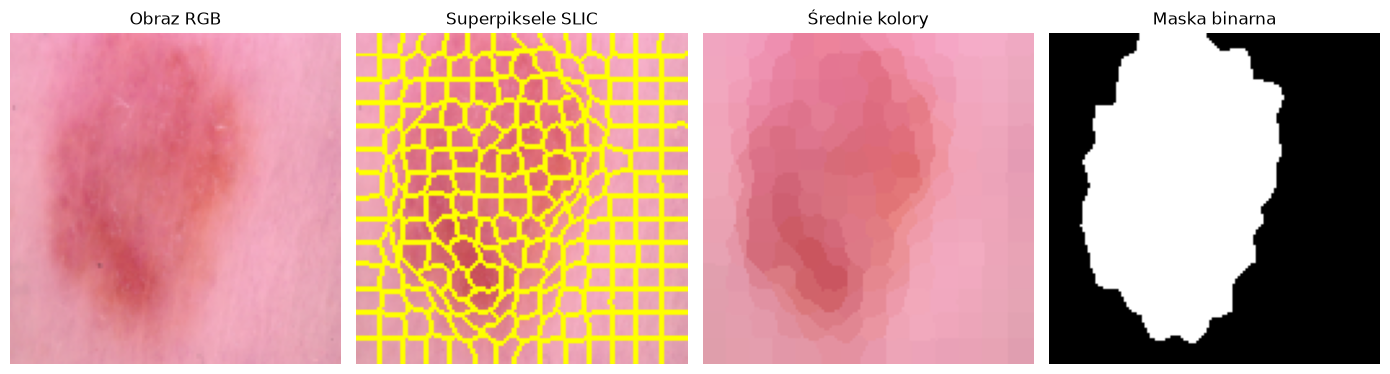

In [5]:
image = X_train_1[77]
mask, superpixels, superpixel_image = segment_superpixels(image)

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(image)
axes[0].set_title('Obraz RGB')
axes[1].imshow(mark_boundaries(image, superpixels))
axes[1].set_title('Superpiksele SLIC')
axes[2].imshow(superpixel_image)
axes[2].set_title('Średnie kolory')
axes[3].imshow(mask, cmap='gray', vmin=0, vmax=1)
axes[3].set_title('Maska binarna')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

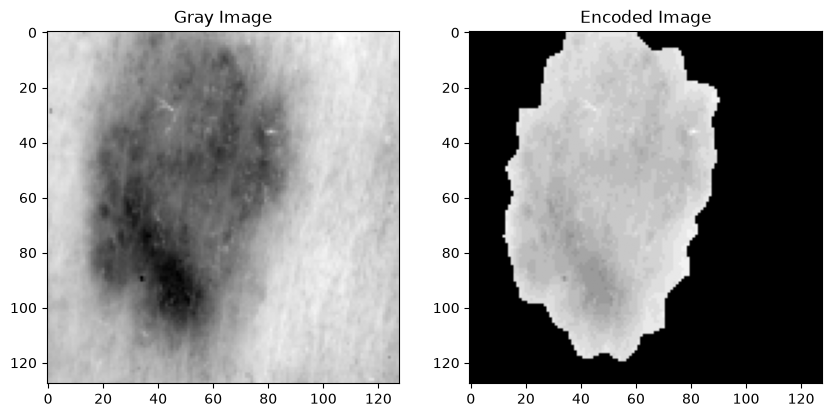

In [6]:
from skimage.util import img_as_float32
from skimage.color import rgb2gray

gray = rgb2gray(img_as_float32(image))
mask = np.asarray(mask, dtype=bool)
quantized = np.minimum((gray * 32).astype(np.int32), 32 - 1)

encoded = np.where(mask, quantized + 1, 0)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(gray, cmap='gray')
axes[0].set_title('Gray Image')
axes[1].imshow(encoded, cmap='gray')
axes[1].set_title('Encoded Image')
plt.show()

In [7]:
import numpy as np
from skimage.color import rgb2gray, rgb2lab
from skimage.feature import graycomatrix, graycoprops
from skimage.measure import regionprops
from skimage.util import img_as_float32

def shape_features(mask):
    mask = np.asarray(mask, dtype=bool)
    if not mask.any():
        raise ValueError("Maska jest pusta.")

    region = regionprops(mask.astype(np.uint8))[0]
    area = float(region.area)
    perimeter = float(region.perimeter)

    return {
        "shape_area": area,
        "shape_area_fraction": area / mask.size,
        "shape_perimeter": perimeter,
        "shape_circularity": 4 * np.pi * area / max(perimeter**2, 1e-12),
        "shape_eccentricity": float(region.eccentricity),
        "shape_solidity": float(region.solidity),
        "shape_extent": float(region.extent),
        "shape_major_axis": float(region.axis_major_length),
        "shape_minor_axis": float(region.axis_minor_length),
        "shape_axis_ratio": (
            region.axis_minor_length / max(region.axis_major_length, 1e-12)
        ),
    }


def color_features(image, mask):
    image = img_as_float32(image)
    mask = np.asarray(mask, dtype=bool)
    if not mask.any():
        raise ValueError("Maska jest pusta.")

    features = {}
    for pixels, channels in [
        (image[mask], ("R", "G", "B")),
        (rgb2lab(image)[mask], ("L", "a", "b")),
    ]:
        for index, channel in enumerate(channels):
            values = pixels[:, index]
            features[f"color_{channel}_mean"] = float(values.mean())
            features[f"color_{channel}_std"] = float(values.std())

    return features


def texture_features(
    image,
    mask,
    levels=32,
    distances=(1, 2),
    angles=(0, np.pi / 4, np.pi / 2, 3 * np.pi / 4),
):
    gray = rgb2gray(img_as_float32(image))
    mask = np.asarray(mask, dtype=bool)
    quantized = np.minimum((gray * levels).astype(np.int32), levels - 1)

    encoded = np.where(mask, quantized + 1, 0)

    glcm = graycomatrix(
        encoded,
        distances=list(distances),
        angles=list(angles),
        levels=levels + 1,
        symmetric=True,
        normed=False,
    )

    glcm = glcm[1:, 1:, :, :].astype(np.float64)
    totals = glcm.sum(axis=(0, 1))
    valid = totals > 0

    if not valid.any():
        raise ValueError("Brak par pikseli wewnątrz maski dla podanych przesunięć.")

    glcm /= np.maximum(totals, 1)[None, None, :, :]

    features = {
        f"glcm_{prop}": float(graycoprops(glcm, prop)[valid].mean())
        for prop in (
            "contrast",
            "dissimilarity",
            "homogeneity",
            "energy",
            "correlation",
            "ASM",
        )
    }

    entropy = -np.sum(
        glcm * np.log2(np.clip(glcm, 1e-12, 1)),
        axis=(0, 1),
    )
    features["glcm_entropy"] = float(entropy[valid].mean())
    return features


def extract_features(image) -> np.ndarray:
    mask, _, _ = segment_superpixels(image) 

    features = {
        **shape_features(mask),
        **color_features(image, mask),
        **texture_features(image, mask),
    }
    return np.array(list(features.values()), dtype=np.float32)

In [8]:
image = X_train_1[0]
mask, _, _ = segment_superpixels(image)

feature_names = [
    *shape_features(mask),
    *color_features(image, mask),
    *texture_features(image, mask),
]

In [ ]:
from sklearn.preprocessing import FunctionTransformer
import pandas as pd

def encode(X):
    return pd.DataFrame(
        [extract_features(img) for img in X],
        columns=feature_names,
    )

transformer_1 = FunctionTransformer(encode, validate=False)
transformer_2 = FunctionTransformer(encode, validate=False)

X_train_1_encoded = transformer_1.fit_transform(X_train_1)
X_test_1_encoded = transformer_1.transform(X_test_1)

X_train_2_encoded = transformer_2.fit_transform(X_train_2)
X_test_2_encoded = transformer_2.transform(X_test_2)

In [78]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report

def experiment(X_train, y_train):
    clf = RandomForestClassifier()
    clf.fit(X_train, y_train)
    
    return clf

def evaluate(clf, X_test, y_test, title):
    y_pred = clf.predict(X_test)
    print(f"Experiment: {title}")
    print(classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=clf.classes_).plot()

Simple Experiment

Experiment: Simple Experiment
              precision    recall  f1-score   support

           0       1.00      0.93      0.96        29
           1       0.93      1.00      0.97        28

    accuracy                           0.96        57
   macro avg       0.97      0.97      0.96        57
weighted avg       0.97      0.96      0.96        57



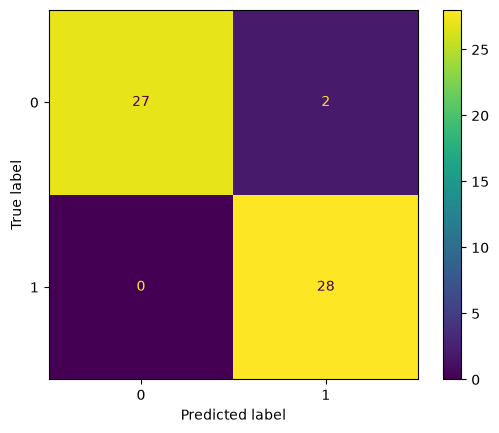

In [79]:
clf_simple = experiment(X_train_1_encoded, y_train_1)
evaluate(clf_simple, X_test_1_encoded, y_test_1, "Simple Experiment")

Experiment: Hard Experiment
              precision    recall  f1-score   support

           0       0.84      0.91      0.88       200
           1       0.90      0.83      0.86       200

    accuracy                           0.87       400
   macro avg       0.87      0.87      0.87       400
weighted avg       0.87      0.87      0.87       400



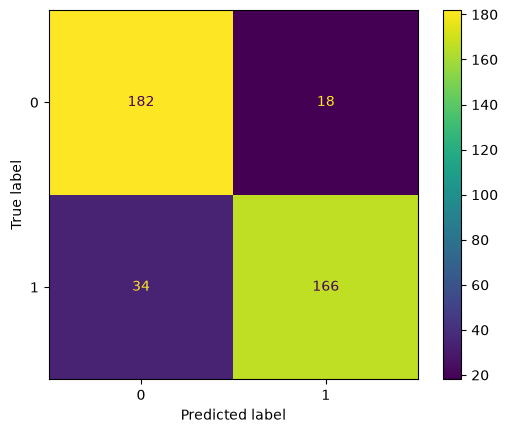

In [56]:
clf_hard = experiment(X_train_2_encoded, y_train_2)
evaluate(clf_hard, X_test_2_encoded, y_test_2, "Hard Experiment")

In [59]:
import pandas as pd

def plot_feature_importance(model, title):
    importance = pd.Series(
        model.feature_importances_,
        index=model.feature_names_in_,
    ).sort_values(ascending=False)
    importance.head(15).sort_values().plot.barh(figsize=(8, 6))
    plt.xlabel("Feature importance")
    plt.title(title)
    plt.tight_layout()
    plt.show()

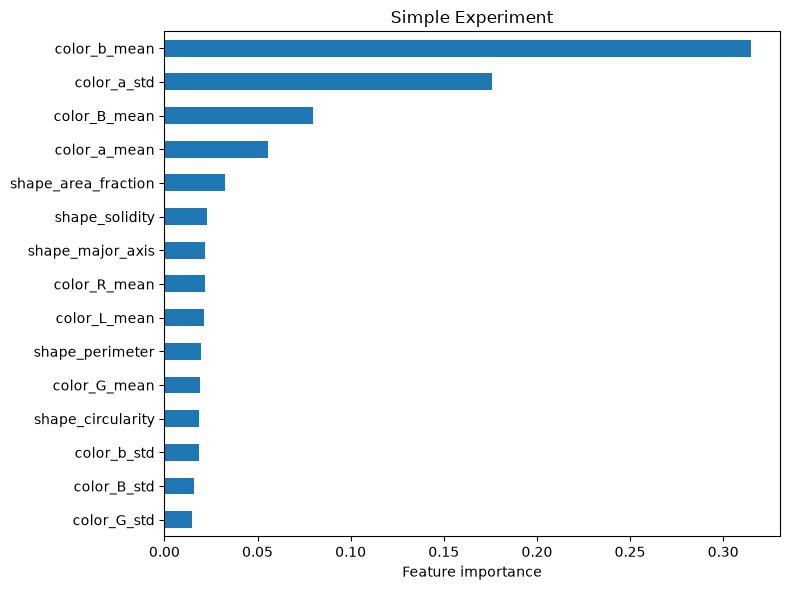

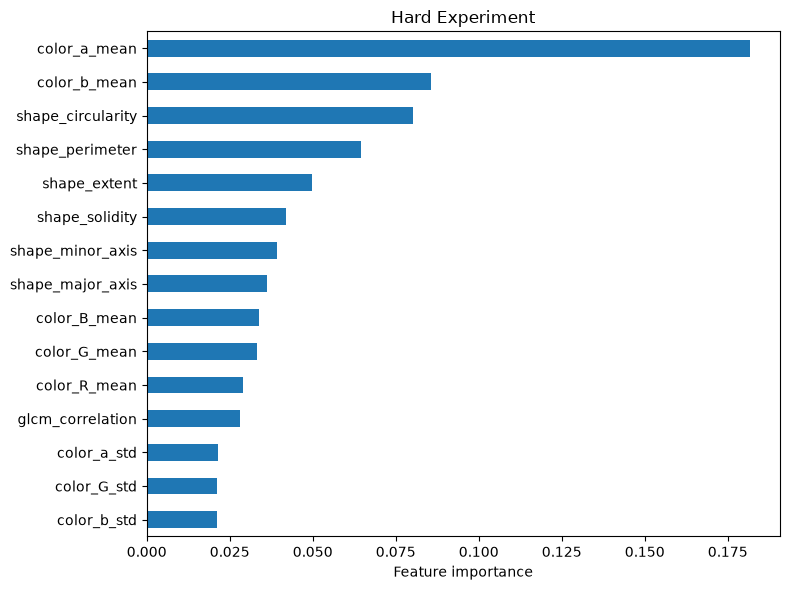

In [60]:
plot_feature_importance(clf_simple, "Simple Experiment")
plot_feature_importance(clf_hard, "Hard Experiment")

## Selekcja cech

In [87]:
X_train_1_encoded.shape, X_train_2_encoded.shape

((227, 29), (1600, 29))

In [63]:
from sklearn.feature_selection import SelectFromModel

simple_feature_selector = SelectFromModel(clf_simple, prefit=True)
X_train_1_selected = simple_feature_selector.fit_transform(X_train_1_encoded)
X_test_1_selected = simple_feature_selector.transform(X_test_1_encoded)
print("Selected features shape:", X_train_1_selected.shape)

hard_feature_selector = SelectFromModel(clf_hard, prefit=True)
X_train_2_selected = hard_feature_selector.fit_transform(X_train_2_encoded)
X_test_2_selected = hard_feature_selector.transform(X_test_2_encoded)
print("Selected features shape:", X_train_2_selected.shape)

Selected features shape: (227, 4)
Selected features shape: (1600, 8)


Experiment: Simple Experiment with Selected Features
              precision    recall  f1-score   support

           0       1.00      0.90      0.95        29
           1       0.90      1.00      0.95        28

    accuracy                           0.95        57
   macro avg       0.95      0.95      0.95        57
weighted avg       0.95      0.95      0.95        57

Experiment: Hard Experiment with Selected Features
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       200
           1       0.87      0.77      0.81       200

    accuracy                           0.82       400
   macro avg       0.83      0.82      0.82       400
weighted avg       0.83      0.82      0.82       400



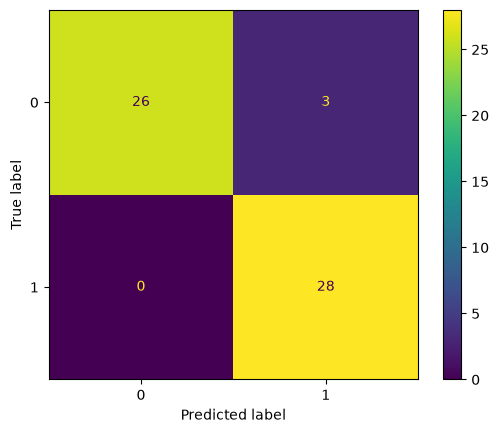

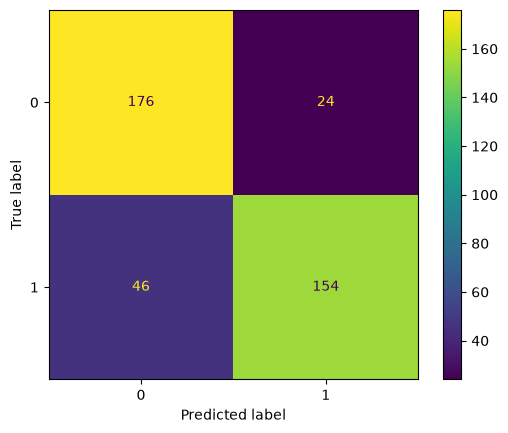

In [64]:
clf_simple_selected = experiment(X_train_1_selected, y_train_1)
evaluate(clf_simple_selected, X_test_1_selected, y_test_1, "Simple Experiment with Selected Features")

clf_hard_selected = experiment(X_train_2_selected, y_train_2)
evaluate(clf_hard_selected, X_test_2_selected, y_test_2, "Hard Experiment with Selected Features")

In [88]:
evaluations = {
    "Simple Experiment": (clf_simple, X_test_1_encoded, y_test_1),
    "Hard Experiment": (clf_hard, X_test_2_encoded, y_test_2),
    "Simple Experiment with Selected Features": (clf_simple_selected, X_test_1_selected, y_test_1),
    "Hard Experiment with Selected Features": (clf_hard_selected, X_test_2_selected, y_test_2)
}

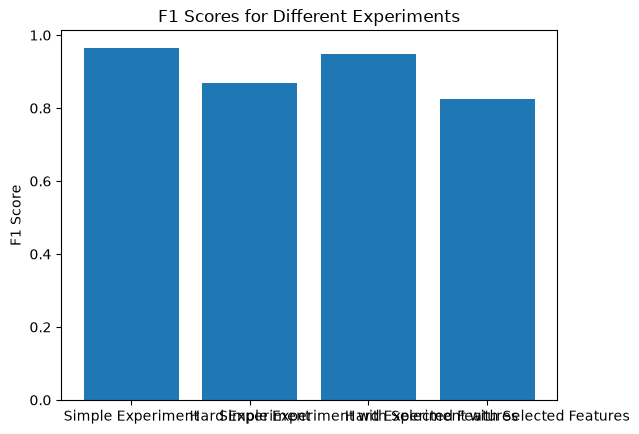

In [89]:
from sklearn.metrics import f1_score

f1_scores = {}

for title, (model, X_test, y_test) in evaluations.items():
    y_pred = model.predict(X_test)
    f1_scores[title] = f1_score(y_test, y_pred, average="weighted")

plt.bar(f1_scores.keys(), f1_scores.values())
plt.ylabel("F1 Score")
plt.title("F1 Scores for Different Experiments")
plt.show()

In [90]:
f1_scores

{'Simple Experiment': 0.9648906749632703,
 'Hard Experiment': 0.8697916666666667,
 'Simple Experiment with Selected Features': 0.9472711053442544,
 'Hard Experiment with Selected Features': 0.8244690187818151}